# 01 - Data Understanding

## Step 1 — Load the dataset

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/raw/customer_support_tickets.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


## Step 2 — Understand the dataset

Inspect dataset dimensions, columns, data types and sample records.

In [3]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())

Dataset Shape: (8469, 17)

Column Names:
['Ticket ID', 'Customer Name', 'Customer Email', 'Customer Age', 'Customer Gender', 'Product Purchased', 'Date of Purchase', 'Ticket Type', 'Ticket Subject', 'Ticket Description', 'Ticket Status', 'Resolution', 'Ticket Priority', 'Ticket Channel', 'First Response Time', 'Time to Resolution', 'Customer Satisfaction Rating']

First 5 Rows:


,Ticket ID,Customer Name,Customer Email,Customer Age,Customer Gender,Product Purchased,Date of Purchase,Ticket Type,Ticket Subject,Ticket Description,Ticket Status,Resolution,Ticket Priority,Ticket Channel,First Response Time,Time to Resolution,Customer Satisfaction Rating
0,1,Marisa Obrien,carrollallison@example.com,32,Other,GoPro Hero,2021-03-22,Technical issue,Product setup,I'm having an issue with the {product_purchase...,Pending Customer Response,NaN,Critical,Social media,2023-06-01 12:15:36,NaN,NaN
1,2,Jessica Rios,clarkeashley@example.com,42,Female,LG Smart TV,2021-05-22,Technical issue,Peripheral compatibility,I'm having an issue with the {product_purchase...,Pending Customer Response,NaN,Critical,Chat,2023-06-01 16:45:38,NaN,NaN
2,3,Christopher Robbins,gonzalestracy@example.com,48,Other,Dell XPS,2020-07-14,Technical issue,Network problem,I'm facing a problem with my {product_purchase...,Closed,Case maybe show recently my computer follow.,Low,Social media,2023-06-01 11:14:38,2023-06-01 18:05:38,3.0
3,4,Christina Dillon,bradleyolson@example.org,27,Female,Microsoft Office,2020-11-13,Billing inquiry,Account access,I'm having an issue with the {product_purchase...,Closed,Try capital clearly never color toward story.,Low,Social media,2023-06-01 07:29:40,2023-06-01 01:57:40,3.0
4,5,Alexander Carroll,bradleymark@example.com,67,Female,Autodesk AutoCAD,2020-02-04,Billing inquiry,Data loss,I'm having an issue with the {product_purchase...,Closed,West decision evidence bit.,Low,Email,2023-06-01 00:12:42,2023-06-01 19:53:42,1.0


## Step 3 — Check data types


In [4]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 8469 entries, 0 to 8468
Data columns (total 17 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Ticket ID                     8469 non-null   int64  
 1   Customer Name                 8469 non-null   str    
 2   Customer Email                8469 non-null   str    
 3   Customer Age                  8469 non-null   int64  
 4   Customer Gender               8469 non-null   str    
 5   Product Purchased             8469 non-null   str    
 6   Date of Purchase              8469 non-null   str    
 7   Ticket Type                   8469 non-null   str    
 8   Ticket Subject                8469 non-null   str    
 9   Ticket Description            8469 non-null   str    
 10  Ticket Status                 8469 non-null   str    
 11  Resolution                    2769 non-null   str    
 12  Ticket Priority               8469 non-null   str    
 13  Ticket Channel

## Step 4 — Basic statistics

In [5]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Ticket ID,8469.0,NaN,NaN,NaN,4235.0,2444.934048,1.0,2118.0,4235.0,6352.0,8469.0
Customer Name,8469,8028,Michael Garcia,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer Email,8469,8320,asmith@example.com,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer Age,8469.0,NaN,NaN,NaN,44.026804,15.296112,18.0,31.0,44.0,57.0,70.0
Customer Gender,8469,3,Male,2896,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product Purchased,8469,42,Canon EOS,240,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date of Purchase,8469,730,2020-10-21,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ticket Type,8469,5,Refund request,1752,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ticket Subject,8469,16,Refund request,576,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ticket Description,8469,8077,I'm having an issue with the {product_purchase...,25,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Step 5 — Missing-value analysis


In [6]:
# Check missing values in each column

missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": (missing_values / len(df)) * 100
})

display(missing_summary.sort_values(
    by="Missing Percentage",
    ascending=False
))

,Missing Values,Missing Percentage
Customer Satisfaction Rating,5700,67.304286
Time to Resolution,5700,67.304286
Resolution,5700,67.304286
First Response Time,2819,33.286102
Ticket Description,0,0.000000
Ticket Channel,0,0.000000
Ticket Priority,0,0.000000
Ticket Status,0,0.000000
Ticket ID,0,0.000000
Customer Name,0,0.000000


## Step 6 — Visualise missing values

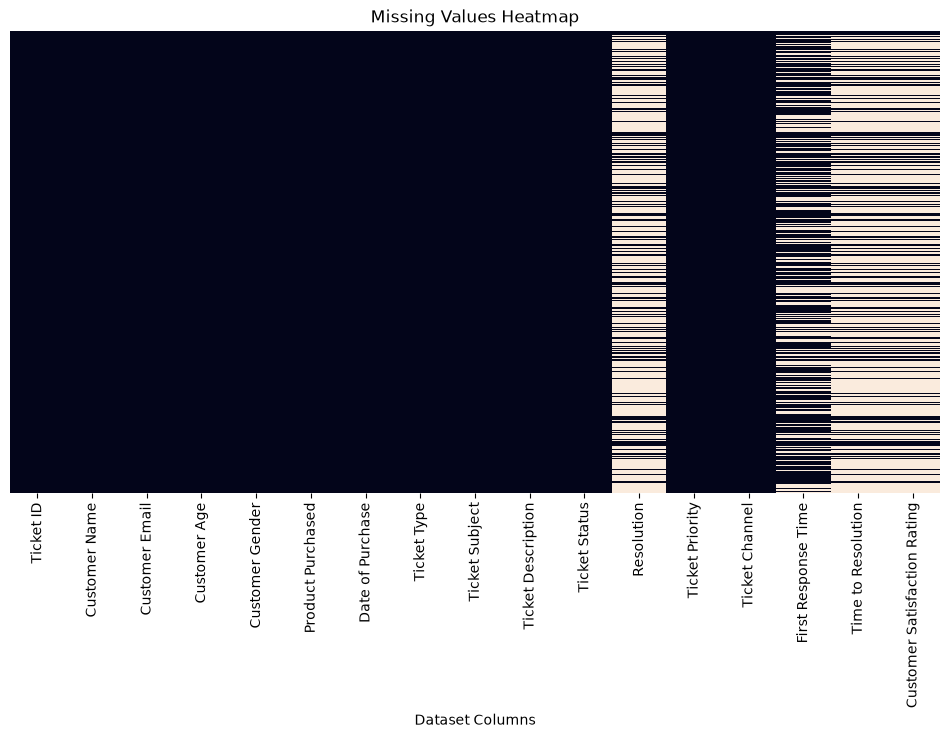

In [7]:
plt.figure(figsize=(12, 6))

sns.heatmap(df.isnull(), cbar=False, yticklabels=False)

plt.title("Missing Values Heatmap")
plt.xlabel("Dataset Columns")
plt.show()

### Missing Values – Initial Observations

The missing values heatmap indicates that missing data is
primarily present in the following columns:

- Resolution
- First Response Time
- Time to Resolution
- Customer Satisfaction Rating

The remaining columns appear to have complete records.

Missing values in resolution and response fields may be related
to ticket processing status. Missing customer satisfaction ratings
may indicate that feedback was not provided.

Further investigation is required before applying any cleaning
operations.

## Step 7 - Check duplicate records

In [8]:
# Check duplicate records

print("Total duplicate rows:", df.duplicated().sum())

print(
    "Duplicate Ticket IDs:",
    df["Ticket ID"].duplicated().sum()
)

Total duplicate rows: 0
Duplicate Ticket IDs: 0


### Duplicate Records – Initial Observations

- Total duplicate rows: 0
- Duplicate Ticket IDs: 0

The dataset contains no exact duplicate records.
Every ticket has a unique Ticket ID.

Therefore, no duplicate-record removal is required
based on these two checks.

## Step 8 - Ticket type analysis

Ticket Type
Refund request          1752
Technical issue         1747
Cancellation request    1695
Product inquiry         1641
Billing inquiry         1634
Name: count, dtype: int64


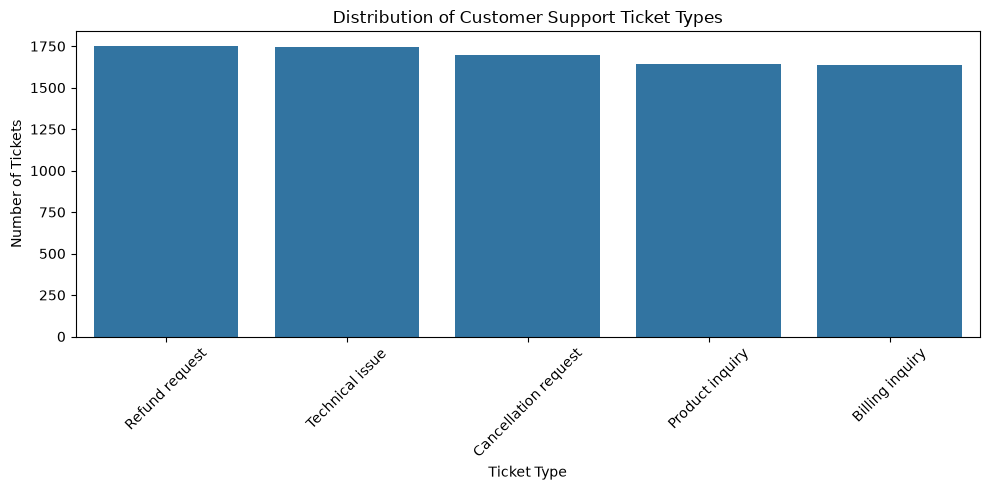

In [9]:
# Analyse ticket types

ticket_type_counts = df["Ticket Type"].value_counts()

print(ticket_type_counts)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=ticket_type_counts.index,
    y=ticket_type_counts.values
)

plt.title("Distribution of Customer Support Ticket Types")
plt.xlabel("Ticket Type")
plt.ylabel("Number of Tickets")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Ticket Type Analysis – Key Observations

- Refund requests: 1,752 tickets.
- Technical issues: 1,747 tickets.
- Cancellation requests: 1,695 tickets.
- Product inquiries: 1,641 tickets.
- Billing inquiries: 1,634 tickets.

Refund requests represent the highest ticket volume,
followed closely by technical issues.

The distribution is relatively balanced across all
five categories.

Business Insight:
Management should investigate refund requests and
technical issues to understand whether additional
support resources or process improvements are needed.

## Step 9 - Customer support channel analysis

Ticket Channel
Email           2143
Phone           2132
Social media    2121
Chat            2073
Name: count, dtype: int64


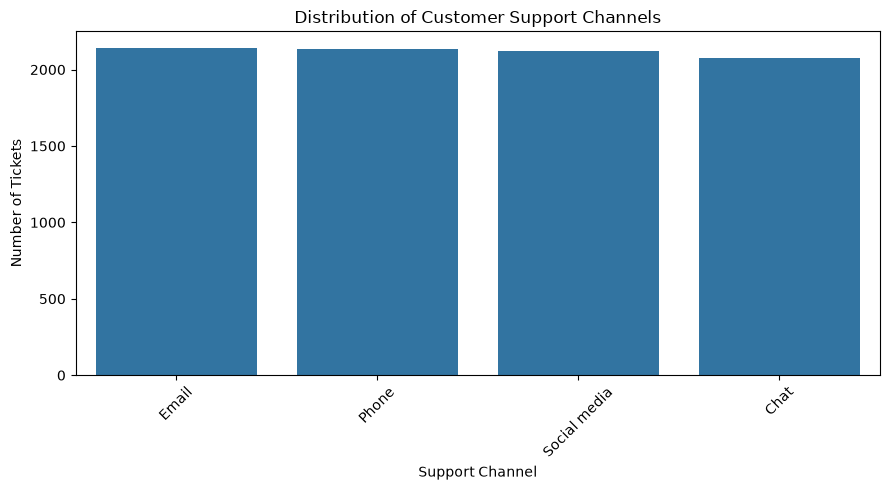

In [10]:
# Analyse ticket channels

channel_counts = df["Ticket Channel"].value_counts()

print(channel_counts)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=channel_counts.index,
    y=channel_counts.values
)

plt.title("Distribution of Customer Support Channels")
plt.xlabel("Support Channel")
plt.ylabel("Number of Tickets")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Step 10 - Support channel analysis

In [11]:
channel_counts = df["Ticket Channel"].value_counts()

channel_summary = pd.DataFrame({
    "Ticket Count": channel_counts,
    "Percentage": (channel_counts / len(df) * 100).round(2)
})

display(channel_summary)

,Ticket Count,Percentage
Ticket Channel,,
Email,2143,25.30
Phone,2132,25.17
Social media,2121,25.04
Chat,2073,24.48


### Customer Support Channel Analysis – Key Findings

- Email: 2,143 tickets (25.30%)
- Phone: 2,132 tickets (25.17%)
- Social Media: 2,121 tickets (25.04%)
- Chat: 2,073 tickets (24.48%)

Email has the highest ticket volume, while Chat has
the lowest.

The distribution is almost equal across all four
communication channels.

Business Insight:
Customer support demand is evenly distributed across
channels. Management should maintain balanced support
resources across Email, Phone, Social Media and Chat.

## Step 10 — Analyse ticket priority

Ticket Priority
Medium      2192
Critical    2129
High        2085
Low         2063
Name: count, dtype: int64


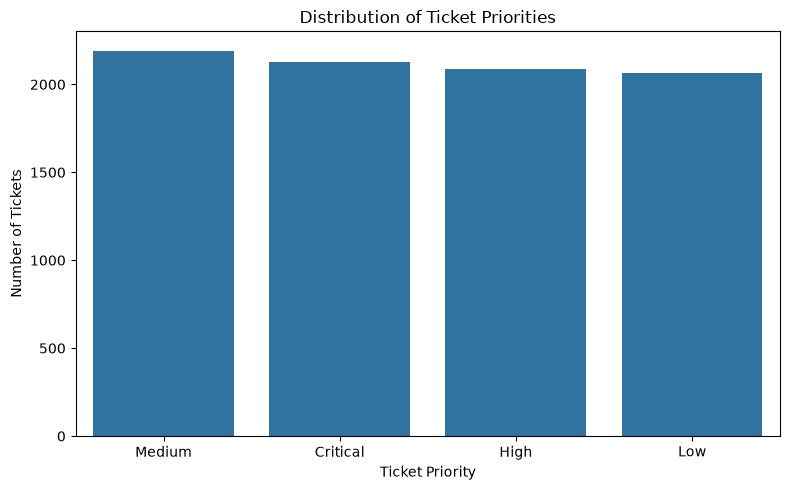

In [12]:
# Analyse ticket priority

priority_counts = df["Ticket Priority"].value_counts()

print(priority_counts)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=priority_counts.index,
    y=priority_counts.values
)

plt.title("Distribution of Ticket Priorities")
plt.xlabel("Ticket Priority")
plt.ylabel("Number of Tickets")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Ticket Priority Analysis – Key Findings

- Medium: 2,192 tickets (25.88%)
- Critical: 2,129 tickets (25.14%)
- High: 2,085 tickets (24.62%)
- Low: 2,063 tickets (24.36%)

Medium priority has the highest ticket volume, while
Low priority has the lowest.

The distribution is relatively balanced across all
four priority categories.

Business Insight:
Management should maintain adequate support resources
across all priority levels and give appropriate attention
to Critical tickets.

Note: Ticket priority does not confirm whether a ticket
was escalated.

## Step 11: Ticket status analysis

Ticket Status
Pending Customer Response    2881
Open                         2819
Closed                       2769
Name: count, dtype: int64


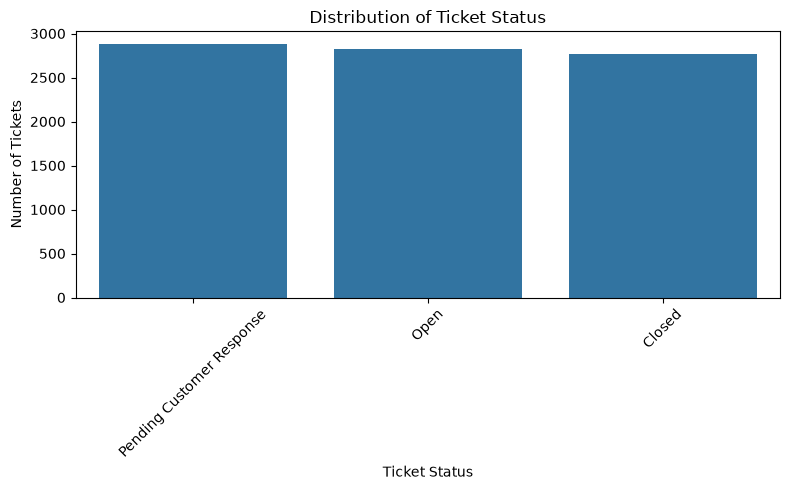

In [13]:
# Analyse ticket status

status_counts = df["Ticket Status"].value_counts()

print(status_counts)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=status_counts.index,
    y=status_counts.values
)

plt.title("Distribution of Ticket Status")
plt.xlabel("Ticket Status")
plt.ylabel("Number of Tickets")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Ticket Status Analysis – Key Findings

- Pending Customer Response: 2,881 (34.02%)
- Open: 2,819 (33.28%)
- Closed: 2,769 (32.69%)

Pending Customer Response has the highest ticket count,
while Closed has the lowest.

The distribution is relatively balanced across the
three ticket statuses.

Business Insight:
Management should review pending customer response
workflows and investigate whether follow-up processes
can be improved.

Note: Ticket status alone does not confirm escalation
or indicate how long a ticket has remained pending.

## Step 12: Initial findings and conclusion


# Initial Data Understanding – Conclusion

### Dataset Overview
- Total records: 8,469
- Total columns: 17
- Duplicate rows: 0
- Duplicate Ticket IDs: 0

### Key Observations

1. Refund requests have the highest ticket type volume.
2. Email is the most frequently used support channel.
3. Medium priority has the highest ticket count.
4. Pending Customer Response is the most common ticket status.
5. Missing values are mainly present in Resolution,
   First Response Time, Time to Resolution and
   Customer Satisfaction Rating.

### Initial Business Insights

- Support demand is distributed across multiple ticket types.
- Customer usage is almost equally distributed across
  all four support channels.
- Priority categories have relatively balanced volumes.
- Pending customer responses deserve further investigation.

### Limitations

- No explicit escalation indicator is available.
- No ticket creation timestamp is available.
- Queue information is unavailable.
- Missing values require further investigation.

### Conclusion

The initial exploratory analysis provides an overview
of customer support ticket patterns, priorities, channels
and statuses.

Further analysis is required to understand service
performance and potential escalation-related risks.